# 🔍 Exploration des agents hors barème

Ce notebook analyse les agents dont le salaire se situe en dehors des bornes min/max du référentiel ANSTAT 2025.

**Source** : `s3://gold/panel_admin/base_avec_statut.parquet` (produit par l'étape 07)

**Rappel** : Chaque ligne = un agent × un mois. Un même agent peut apparaître plusieurs fois.

## 1. Chargement des données

In [1]:
import io
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import polars as pl
import warnings
# warnings.filterwarnings('ignore')

from dotenv import load_dotenv
import boto3
from botocore.client import Config

load_dotenv(".env")

s3 = boto3.client(
    "s3",
    endpoint_url          = os.getenv("MINIO_ENDPOINT"),
    aws_access_key_id     = os.getenv("MINIO_ACCESS_KEY"),
    aws_secret_access_key = os.getenv("MINIO_SECRET_KEY"),
    config                = Config(signature_version="s3v4"),
    region_name           = "us-east-1",
    verify                = False,
)

# Charger base_avec_statut.parquet (TOUS les agents, conformes et hors barème)
buf = io.BytesIO()
s3.download_fileobj("gold", "panel_admin/base_avec_statut.parquet", buf)
buf.seek(0)
base = pl.read_parquet(buf)

print(f"Base complète : {len(base):,} lignes × {len(base.columns)} colonnes")
print(f"Colonnes : {base.columns}")

# --- Variables du salaire utilisée---
col_id  = "matricule"
col_sal = "montant_brut_bareme"

# --- Variable du sexe (recherche dynamique) ---
col_sexe = next((c for c in ["SEXE_STD", "sexe"] if c in base.columns), None)

print(f"\nIdentifiant : {col_id}")
print(f"Colonne salaire : {col_sal}")

base.tail(10)

Base complète : 6,914,095 lignes × 55 colonnes
Colonnes : ['cle_unique', 'matricule', 'nom', 'sexe', 'date_naissance', 'situation_matrimoniale', 'nombre_enfant', 'situation_normalisee', 'CODE_ORGANISME', 'organisme', 'CODE_EMPLOI', 'emploi', 'Code_CITP', 'Metier_CITP', 'CODE_GRADE', 'grade', 'statut_fonctionnaire', 'CODE_FONCTION', 'fonction', 'CODE_SERVICE', 'service', 'CODE_AFFECTATION', 'lieu_affectation', 'CODE_POSTE', 'prise_service', 'date_retraite', 'age_retraite', 'GRADE', 'GRADE_SOURCE', 'mois_annee', 'annee', 'mois', 'montant_brut', 'montant_net', 'retenue_pension', 'impot', 'charge_patronale', 'montant_brut_SOURCE', 'montant_net_SOURCE', 'fichier_source', 'NB_POSTES', 'montant_brut_total', 'montant_brut_bareme', 'montant_net_total', 'ANNEE', 'MOIS_NUM', 'MOIS', 'SALAIRE_BRUT', 'SEXE_STD', 'bareme', 'grade_ref', 'bareme_detail', 'min_bareme', 'max_bareme', 'Statut']

Identifiant : matricule
Colonne salaire : montant_brut_bareme


cle_unique,matricule,nom,sexe,date_naissance,situation_matrimoniale,nombre_enfant,situation_normalisee,CODE_ORGANISME,organisme,CODE_EMPLOI,emploi,Code_CITP,Metier_CITP,CODE_GRADE,grade,statut_fonctionnaire,CODE_FONCTION,fonction,CODE_SERVICE,service,CODE_AFFECTATION,lieu_affectation,CODE_POSTE,prise_service,date_retraite,age_retraite,GRADE,GRADE_SOURCE,mois_annee,annee,mois,montant_brut,montant_net,retenue_pension,impot,charge_patronale,montant_brut_SOURCE,montant_net_SOURCE,fichier_source,NB_POSTES,montant_brut_total,montant_brut_bareme,montant_net_total,ANNEE,MOIS_NUM,MOIS,SALAIRE_BRUT,SEXE_STD,bareme,grade_ref,bareme_detail,min_bareme,max_bareme,Statut
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,i32,f64,f64,f64,f64,f64,str,str,str,u32,f64,f64,f64,i32,i32,str,f64,str,str,str,str,f64,f64,str
"""921778G22""","""921778G""","""YOMAN OHOUEU ADOLPHE""","""Masculin""","""1985-01-01""","""Célibataire""","""0""","""en_activite""","""22""","""Min. de l'Education Nationale …","""29YT""","""Instituteur Adjoint décret 200…","""2341""","""Enseignants du primaire""","""41""","""2ème Classe 1er Echelon""","""Fonctionnaire Catégorie C3""",null,""" ""","""2221""","""Direction des Ressources Humai…","""5PL""","""GBONGAHA""",null,"""2024-09-09""",null,null,"""C3""","""OBSERVE""","""102025""",2025,10,3.61558e6,3.103356e6,137101.0,182840.0,274366.587035,"""OBSERVE""","""OBSERVE""","""102025.xlsx""",1,3.61558e6,3.560723e6,3.103356e6,2025,10,"""Octobre""",3.560723e6,"""Homme""","""ENS SEC & PRIM""","""C3""","""ENS SEC & PRIM_PRIM""",279274.0,362502.0,"""Supérieur au maximum du barème"""
"""921778G22""","""921778G""","""YOMAN OHOUEU ADOLPHE""","""Masculin""","""1985-01-01""","""Célibataire""","""0""","""en_activite""","""22""","""Min. de l'Education Nationale …","""29YT""","""Instituteur Adjoint décret 200…","""2341""","""Enseignants du primaire""","""41""","""2ème Classe 1er Echelon""","""Fonctionnaire Catégorie C3""",null,""" ""","""2221""","""Direction des Ressources Humai…","""5PL""","""GBONGAHA""",null,"""2024-09-09""",null,null,"""C3""","""OBSERVE""","""112025""",2025,11,259276.0,214115.0,13710.0,18284.0,27436.458583,"""OBSERVE""","""OBSERVE""","""112025.xlsx""",1,259276.0,259276.0,214115.0,2025,11,"""Novembre""",259276.0,"""Homme""","""ENS SEC & PRIM""","""C3""","""ENS SEC & PRIM_PRIM""",279274.0,362502.0,"""Inférieur au minimum du barème"""
"""921778G22""","""921778G""","""YOMAN OHOUEU ADOLPHE""","""Masculin""","""1985-01-01""","""Célibataire""","""0""","""en_activite""","""22""","""Min. de l'Education Nationale …","""29YT""","""Instituteur Adjoint décret 200…","""2341""","""Enseignants du primaire""","""41""","""2ème Classe 1er Echelon""","""Fonctionnaire Catégorie C3""",null,""" ""","""2221""","""Direction des Ressources Humai…","""5PL""","""GBONGAHA""",null,"""2024-09-09""",null,null,"""C3""","""OBSERVE""","""122025""",2025,12,259276.0,214116.0,13710.0,18284.0,27436.458583,"""OBSERVE""","""OBSERVE""","""122025.xlsx""",1,259276.0,259276.0,214116.0,2025,12,"""Décembre""",259276.0,"""Homme""","""ENS SEC & PRIM""","""C3""","""ENS SEC & PRIM_PRIM""",279274.0,362502.0,"""Inférieur au minimum du barème"""
"""921782M22""","""921782M""","""ZELE GONAYO YVANE LERHOU""","""Masculin""","""1994-12-22""","""Célibataire""","""0""","""en_activite""","""22""","""Min. de l'Education Nationale …","""29YT""","""Instituteur Adjoint décret 200…","""2341""","""Enseignants du primaire""","""41""","""2ème Classe 1er Echelon""","""Fonctionnaire Catégorie C3""",null,""" ""","""2221""","""Direction des Ressources Humai…","""4MA""","""Mankono""",null,"""2024-09-09""",null,null,"""C3""","""OBSERVE""","""102025""",2025,10,3.684247e6,3.172023e6,137101.0,182840.0,274366.587035,"""OBSERVE""","""OBSERVE""","""102025.xlsx""",1,3.684247e6,3.62939e6,3.172023e6,2025,10,"""Octobre""",3.62939e6,"""Homme""","""ENS SEC & PRIM""","""C3""","""ENS SEC & PRIM_PRIM""",279274.0,362502.0,"""Supérieur au maxim

## 2. Vue d'ensemble : lignes vs agents uniques

In [2]:
# Distribution des statuts (en lignes)
print("=" * 60)
print("DISTRIBUTION DES STATUTS (en lignes agent × mois)")
print("=" * 60)

n_total = len(base)
statut_counts = base["Statut"].value_counts().sort("count", descending=True)
for row in statut_counts.iter_rows(named=True):
    pct = 100 * row["count"] / n_total
    print(f"  {row['Statut']:<40} : {row['count']:>10,}  ({pct:.1f}%)")
print(f"  {'TOTAL':<40} : {n_total:>10,}")

DISTRIBUTION DES STATUTS (en lignes agent × mois)
  Conforme au barème                       :  6,458,499  (93.4%)
  Inférieur au minimum du barème           :    304,807  (4.4%)
  Supérieur au maximum du barème           :    142,795  (2.1%)
  Cluster non déterminé                    :      7,994  (0.1%)
  TOTAL                                    :  6,914,095


In [3]:
# Agents UNIQUES par statut — avec min/moyenne/médiane/max du nombre de mois
print("=" * 60)
print("DISTRIBUTION DES STATUTS (en agents UNIQUES)")
print("=" * 60)

# Étape 1 : compter le nombre de mois par agent par statut
mois_par_agent = (
    base.group_by(["Statut", col_id])
    .agg(pl.len().alias("nb_mois"))
)

# Étape 2 : agréger min / moyenne / médiane / max par statut
agents_par_statut = (
    mois_par_agent.group_by("Statut")
    .agg([
        pl.col(col_id).n_unique().alias("Agents_uniques"),
        pl.col("nb_mois").sum().alias("Nb_lignes"),
        pl.col("nb_mois").min().alias("Mois_min"),
        pl.col("nb_mois").mean().round(1).alias("Moyenne"),
        pl.col("nb_mois").max().alias("Mois_max"),
    ])
    .sort("Agents_uniques", descending=True)
)
print(agents_par_statut)

DISTRIBUTION DES STATUTS (en agents UNIQUES)
shape: (4, 6)
┌────────────────────────────────┬────────────────┬───────────┬──────────┬─────────┬──────────┐
│ Statut                         ┆ Agents_uniques ┆ Nb_lignes ┆ Mois_min ┆ Moyenne ┆ Mois_max │
│ ---                            ┆ ---            ┆ ---       ┆ ---      ┆ ---     ┆ ---      │
│ str                            ┆ u32            ┆ u32       ┆ u32      ┆ f64     ┆ u32      │
╞════════════════════════════════╪════════════════╪═══════════╪══════════╪═════════╪══════════╡
│ Conforme au barème             ┆ 300473         ┆ 6458499   ┆ 1        ┆ 21.5    ┆ 24       │
│ Supérieur au maximum du barème ┆ 104754         ┆ 142795    ┆ 1        ┆ 1.4     ┆ 24       │
│ Inférieur au minimum du barème ┆ 36303          ┆ 304807    ┆ 1        ┆ 8.4     ┆ 24       │
│ Cluster non déterminé          ┆ 424            ┆ 7994      ┆ 1        ┆ 18.9    ┆ 24       │
└────────────────────────────────┴────────────────┴───────────┴──────────┴───

In [24]:
# Agents hors barème pendant TOUS les mois disponibles
mois_par_agent_hors = (
    base.filter(pl.col("Statut").is_in([
        "Inférieur au minimum du barème",
        "Supérieur au maximum du barème",
    ]))
    .group_by([col_id, "Statut"])
    .agg(pl.len().alias("nb_mois"))
)

# Nombre total de mois dans la base
nb_mois_total = base.select(pl.col("mois_annee").n_unique()).item()
print(f"Nombre total de mois dans la base : {nb_mois_total}")

# Distribution : combien d'agents par nombre de mois hors barème
print("\n" + "=" * 60)
print("DISTRIBUTION : combien de mois chaque agent est hors barème")
print("=" * 60)

distrib = (
    mois_par_agent_hors
    .group_by(["Statut", "nb_mois"])
    .agg(pl.col(col_id).n_unique().alias("Nb_agents"))
    .sort(["Statut", "nb_mois"])
)
print(distrib)

# Focus : agents hors barème TOUS les mois (nb_mois == nb_mois_total)
print("\n" + "=" * 60)
print(f"AGENTS HORS BARÈME SUR LES {nb_mois_total} MOIS (100% du temps)")
print("=" * 60)

agents_permanents = mois_par_agent_hors.filter(pl.col("nb_mois") == nb_mois_total)
n_perm = len(agents_permanents)
n_total_hors = len(mois_par_agent_hors)

print(f"Agents hors barème 100% du temps : {n_perm:,} / {n_total_hors:,} ({100*n_perm/n_total_hors:.1f}%)")

par_statut = (
    agents_permanents
    .group_by("Statut")
    .agg(pl.len().alias("Nb_agents"))
)
print(par_statut)

# Examiner ces agents permanents
if n_perm > 0:
    ids_permanents = agents_permanents[col_id].to_list()
    detail_perm = base.filter(pl.col(col_id).is_in(ids_permanents))

    # Un résumé par agent (première ligne)
    agg_cols = [
        pl.col("Statut").first(),
    ]
    if "GRADE" in detail_perm.columns:
        agg_cols.append(pl.col("GRADE").first())
    if "GRADE_SOURCE" in detail_perm.columns:
        agg_cols.append(pl.col("GRADE_SOURCE").first())
    if "bareme" in detail_perm.columns:
        agg_cols.append(pl.col("bareme").first())
    if "emploi" in detail_perm.columns:
        agg_cols.append(pl.col("emploi").first())
    if col_sal and col_sal in detail_perm.columns:
        agg_cols.append(pl.col(col_sal).mean().round(0).alias("Salaire_moyen"))
    if "min_bareme" in detail_perm.columns:
        agg_cols.append(pl.col("min_bareme").first().alias("Borne_min"))
    if "max_bareme" in detail_perm.columns:
        agg_cols.append(pl.col("max_bareme").first().alias("Borne_max"))

    resume_perm = detail_perm.group_by(col_id).agg(agg_cols)

    print(f"\nProfil des {min(n_perm, 20)} premiers agents hors barème :")
    print(resume_perm.head(20))

Nombre total de mois dans la base : 24

DISTRIBUTION : combien de mois chaque agent est hors barème
shape: (48, 3)
┌────────────────────────────────┬─────────┬───────────┐
│ Statut                         ┆ nb_mois ┆ Nb_agents │
│ ---                            ┆ ---     ┆ ---       │
│ str                            ┆ u32     ┆ u32       │
╞════════════════════════════════╪═════════╪═══════════╡
│ Inférieur au minimum du barème ┆ 1       ┆ 3889      │
│ Inférieur au minimum du barème ┆ 2       ┆ 3018      │
│ Inférieur au minimum du barème ┆ 3       ┆ 2912      │
│ Inférieur au minimum du barème ┆ 4       ┆ 2049      │
│ Inférieur au minimum du barème ┆ 5       ┆ 2657      │
│ …                              ┆ …       ┆ …         │
│ Supérieur au maximum du barème ┆ 20      ┆ 22        │
│ Supérieur au maximum du barème ┆ 21      ┆ 32        │
│ Supérieur au maximum du barème ┆ 22      ┆ 25        │
│ Supérieur au maximum du barème ┆ 23      ┆ 36        │
│ Supérieur au maximum du barè

In [7]:
# Agents qui sont PARFOIS conforme et PARFOIS hors barème
print("=" * 60)
print("AGENTS PARFOIS CONFORME ET PARFOIS HORS BAREME")
print("=" * 60)

profil = (
    base.group_by(col_id)
    .agg([
        (pl.col("Statut") == "Conforme au barème").any().alias("a_ete_conforme"),
        (pl.col("Statut") != "Conforme au barème").any().alias("a_ete_hors"),
    ])
)

n_mixte = int((profil["a_ete_conforme"] & profil["a_ete_hors"]).sum())
n_agents_total = len(profil)

print(f"Agents parfois conforme, parfois hors barème : {n_mixte:,}  "
      f"({100*n_mixte/n_agents_total:.1f}%)")
print("→ Ces agents changent de catégorie selon les mois (salaire variable)")


AGENTS PARFOIS CONFORME ET PARFOIS HORS BAREME
Agents parfois conforme, parfois hors barème : 105,880  (34.0%)
→ Ces agents changent de catégorie selon les mois (salaire variable)


NameError: name 'mpatches' is not defined

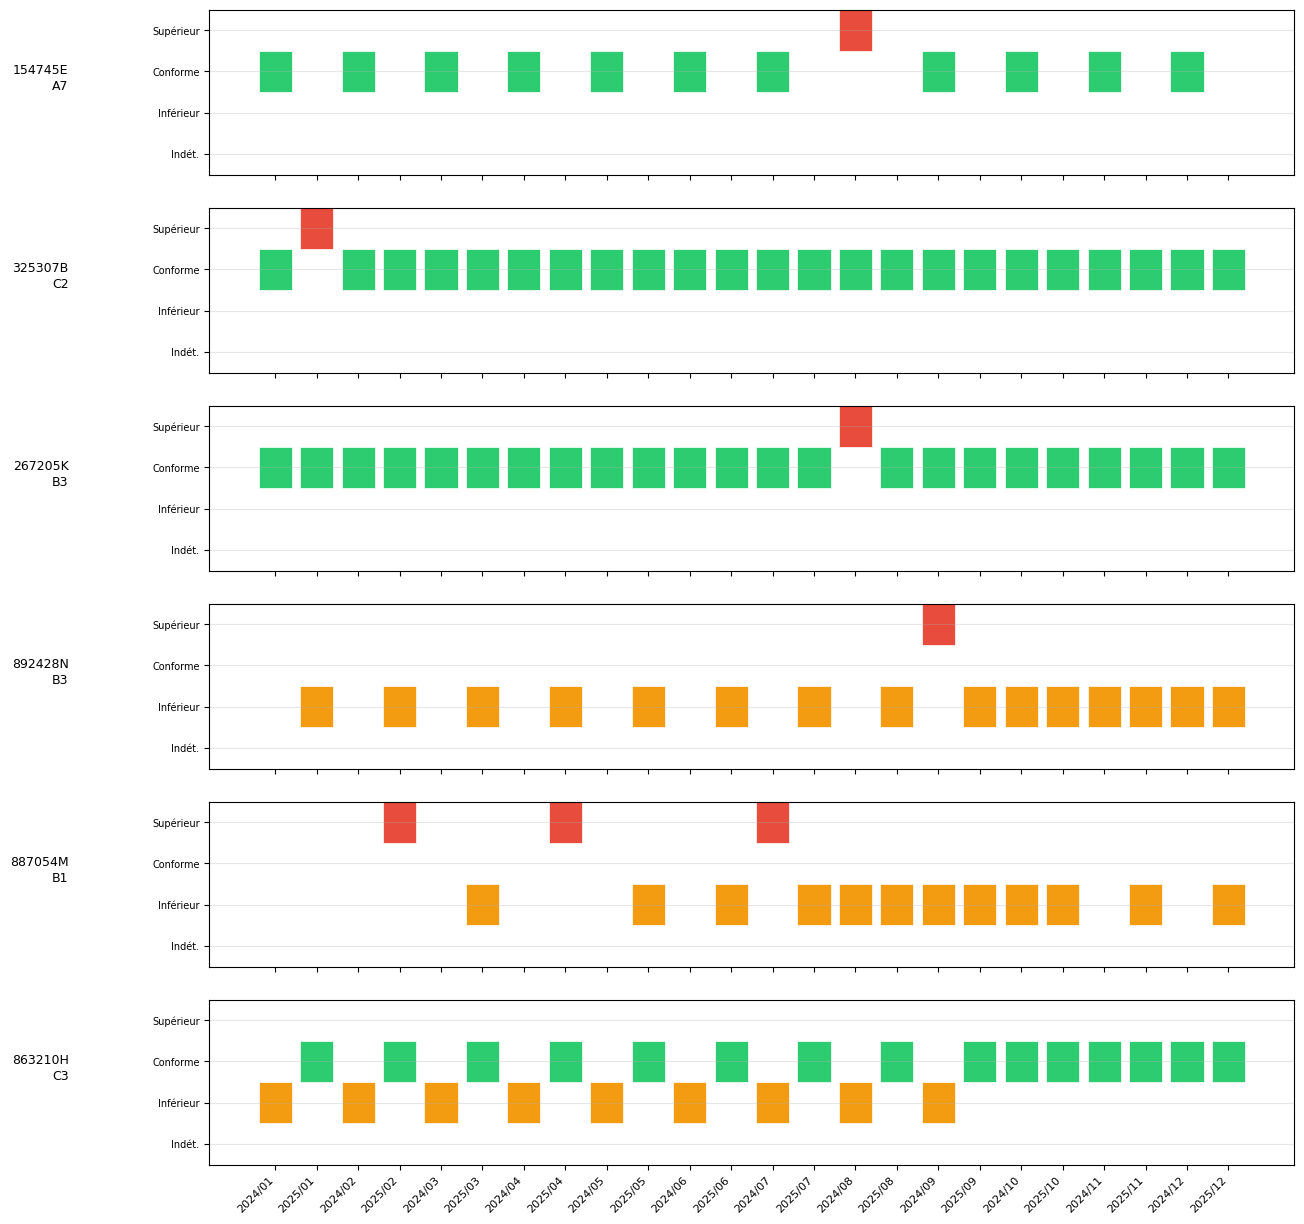

In [8]:
# --- Sélectionner des agents "mixtes" (ceux qui changent de statut) ---
agents_mixtes = (
    base.group_by(col_id)
    .agg(pl.col("Statut").n_unique().alias("nb_statuts"))
    .filter(pl.col("nb_statuts") > 1)
)

# Prendre 6 agents mixtes au hasard pour la visualisation
echantillon_ids = agents_mixtes.sample(6, seed=42)[col_id].to_list()

# Mapping statut → valeur numérique + couleur
statut_map = {
    "Conforme au barème": 2,
    "Supérieur au maximum du barème": 3,
    "Inférieur au minimum du barème": 1,
    "Cluster non déterminé": 0,
}
couleurs = {
    2: "#2ecc71",  # Vert = conforme
    3: "#e74c3c",  # Rouge = supérieur
    1: "#f39c12",  # Orange = inférieur
    0: "#95a5a6",  # Gris = indéterminé
}

# Trier les mois_annee chronologiquement
mois_ordre = sorted(base["mois_annee"].unique().to_list())
mois_index = {m: i for i, m in enumerate(mois_ordre)}

# --- Tracer ---
fig, axes = plt.subplots(len(echantillon_ids), 1, figsize=(14, 2.5 * len(echantillon_ids)), sharex=True)
if len(echantillon_ids) == 1:
    axes = [axes]

for ax, agent_id in zip(axes, echantillon_ids):
    agent_data = base.filter(pl.col(col_id) == agent_id).sort("mois_annee")
    
    x_vals = [mois_index[m] for m in agent_data["mois_annee"].to_list()]
    y_vals = [statut_map.get(s, 0) for s in agent_data["Statut"].to_list()]
    colors = [couleurs[y] for y in y_vals]
    
    # Barres colorées pour chaque mois
    ax.bar(x_vals, [1]*len(x_vals), bottom=[y - 0.5 for y in y_vals], 
           color=colors, width=0.8, edgecolor="white", linewidth=0.5)
    
    # Infos agent
    grade = agent_data["GRADE"][0] if "GRADE" in agent_data.columns else "?"
    bareme = agent_data["bareme"][0] if "bareme" in agent_data.columns else "?"
    ax.set_ylabel(f"{agent_id}\n{grade}", fontsize=9, rotation=0, labelpad=60, ha="right")
    ax.set_yticks([0, 1, 2, 3])
    ax.set_yticklabels(["Indét.", "Inférieur", "Conforme", "Supérieur"], fontsize=7)
    ax.set_ylim(-0.5, 3.5)
    ax.grid(axis="y", alpha=0.3)

# Axe X : mois
axes[-1].set_xticks(range(len(mois_ordre)))
axes[-1].set_xticklabels(
    [f"{m[2:]}/{m[:2]}" for m in mois_ordre],  # Format: 2024/01
    rotation=45, fontsize=8, ha="right"
)

# Légende
legend_patches = [
    mpatches.Patch(color="#2ecc71", label="Conforme"),
    mpatches.Patch(color="#f39c12", label="Inférieur au minimum"),
    mpatches.Patch(color="#e74c3c", label="Supérieur au maximum"),
    mpatches.Patch(color="#95a5a6", label="Cluster non déterminé"),
]
fig.legend(handles=legend_patches, loc="upper center", ncol=4, fontsize=10,
           bbox_to_anchor=(0.5, 1.02))

fig.suptitle("Évolution du statut barème par mois — Agents mixtes (échantillon)", 
             fontsize=13, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()


## 3. Filtrage : agents hors barème uniquement

In [10]:
# Filtrer les hors barème
hors = base.filter(
    pl.col("Statut").is_in([
        "Inférieur au minimum du barème",
        "Supérieur au maximum du barème",
    ])
)

print(f"Lignes hors barème    : {len(hors):,}")
print(f"Agents uniques        : {hors[col_id].n_unique():,}")
print(f"Colonne salaire       : {col_sal}")

# Aperçu
print("\nAperçu des données :")
cols_apercu = [c for c in [col_id, "mois_annee", "ANNEE", col_sal, 
               "min_bareme", "max_bareme", "Statut", "GRADE", "bareme"]
               if c and c in hors.columns]
hors.select(cols_apercu).head(10)

Lignes hors barème    : 447,602
Agents uniques        : 116,678
Colonne salaire       : montant_brut_bareme

Aperçu des données :


matricule,mois_annee,ANNEE,montant_brut_bareme,min_bareme,max_bareme,Statut,GRADE,bareme
str,str,i32,f64,f64,f64,str,str,str
"""108076E""","""022024""",2024,935876.0,379078.0,687823.0,"""Supérieur au maximum du barème""","""A5""","""Barême Général"""
"""110082J""","""082024""",2024,999375.0,457071.0,819511.0,"""Supérieur au maximum du barème""","""A4""","""ENS SEC & PRIM"""
"""112035G""","""012024""",2024,582592.0,646210.0,750915.0,"""Inférieur au minimum du barème""","""A7""","""Barême Général"""
"""112035G""","""032024""",2024,605411.0,646210.0,750915.0,"""Inférieur au minimum du barème""","""A7""","""Barême Général"""
"""112035G""","""042024""",2024,605411.0,646210.0,750915.0,"""Inférieur au minimum du barème""","""A7""","""Barême Général"""
"""112035G""","""052024""",2024,605411.0,646210.0,750915.0,"""Inférieur au minimum du barème""","""A7""","""Barême Général"""
"""112035G""","""062024""",2024,605411.0,646210.0,750915.0,"""Inférieur au minimum du barème""","""A7""","""Barême Général"""
"""112035G""","""072024""",2024,605411.0,646210.0,750915.0,"""Inférieur au minimum du barème""","""A7""","""Barême Général"""
"""112055L""","""012024""",2024,701900.0,340285.0,662454.0,"""Supérieur au maximum du barème""","""A4""","""Barême Général"""


In [11]:
# ==============================================================================
# EXPORT VERS EXCEL : Liste détaillée des agents hors barème
# ==============================================================================

print("Préparation de l'export Excel...")

# 1. On regroupe les données pour avoir UNE SEULE ligne par agent
profil_export = (
    hors
    .group_by([col_id, "Statut"])
    .agg([
        pl.len().alias("Nb_mois_hors_bareme"),
        pl.col("GRADE").first().alias("Grade"),
        pl.col("GRADE_SOURCE").first().alias("Source_du_grade"),
        pl.col("bareme").first().alias("Secteur_bareme"),
        pl.col("emploi").first().alias("Emploi"),
        pl.col(col_sal).mean().round(0).alias("Salaire_moyen_FCFA"),
        pl.col("min_bareme").first().alias("Borne_min_ref"),
        pl.col("max_bareme").first().alias("Borne_max_ref"),
        # Si la colonne ecart_pct existe, on l'ajoute
        pl.col("ecart_pct").mean().round(1).alias("Ecart_moyen_%") if "ecart_pct" in hors.columns else pl.lit(None).alias("Ecart_moyen_%")
    ])
    .sort(["Statut", "Nb_mois_hors_bareme"], descending=[False, True])
)

# 2. Exporter le résultat en Excel
nom_fichier = "agents_hors_bareme_export.xlsx"

try:
    # Polars possède une fonction native pour écrire en Excel (nécessite xlsxwriter)
    profil_export.write_excel(nom_fichier)
    print(f"✅ Export réussi !")
    print(f"Le fichier '{nom_fichier}' a été créé dans le dossier courant.")
    print(f"Il contient {len(profil_export):,} agents.")
except ImportError:
    # Si le package xlsxwriter n'est pas installé, on exporte en CSV par sécurité
    nom_fichier_csv = "agents_hors_bareme_export.csv"
    profil_export.write_csv(nom_fichier_csv)
    print(f"⚠️ Le module 'xlsxwriter' n'est pas installé.")
    print(f"✅ Export de secours réussi en CSV : '{nom_fichier_csv}'")


Préparation de l'export Excel...
✅ Export réussi !
Le fichier 'agents_hors_bareme_export.xlsx' a été créé dans le dossier courant.
Il contient 141,057 agents.


## 4. Analyse des écarts au barème

**De combien les agents dépassent-ils les bornes ?**

In [12]:
# Calculer l'écart au barème
if col_sal and "min_bareme" in hors.columns and "max_bareme" in hors.columns:
    hors = hors.with_columns([
        # Écart en FCFA
        pl.when(pl.col("Statut") == "Inférieur au minimum du barème")
          .then(pl.col(col_sal) - pl.col("min_bareme"))
          .otherwise(pl.col(col_sal) - pl.col("max_bareme"))
          .alias("ecart_fcfa"),
        # Écart en %
        pl.when(pl.col("Statut") == "Inférieur au minimum du barème")
          .then(((pl.col(col_sal) - pl.col("min_bareme")) / pl.col("min_bareme") * 100).round(1))
          .otherwise(((pl.col(col_sal) - pl.col("max_bareme")) / pl.col("max_bareme") * 100).round(1))
          .alias("ecart_pct"),
    ])
    
    print("Écart au barème par statut :")
    print(
        hors.group_by("Statut")
        .agg([
            pl.len().alias("Nb_lignes"),
            pl.col("ecart_fcfa").mean().round(0).alias("Ecart_moyen_FCFA"),
            pl.col("ecart_fcfa").median().round(0).alias("Ecart_median_FCFA"),
            pl.col("ecart_pct").mean().round(1).alias("Ecart_moyen_%"),
            pl.col("ecart_pct").median().round(1).alias("Ecart_median_%"),
        ])
        .sort("Statut")
    )

Écart au barème par statut :
shape: (2, 6)
┌─────────────────┬───────────┬─────────────────┬─────────────────┬───────────────┬────────────────┐
│ Statut          ┆ Nb_lignes ┆ Ecart_moyen_FCF ┆ Ecart_median_FC ┆ Ecart_moyen_% ┆ Ecart_median_% │
│ ---             ┆ ---       ┆ A               ┆ FA              ┆ ---           ┆ ---            │
│ str             ┆ u32       ┆ ---             ┆ ---             ┆ f64           ┆ f64            │
│                 ┆           ┆ f64             ┆ f64             ┆               ┆                │
╞═════════════════╪═══════════╪═════════════════╪═════════════════╪═══════════════╪════════════════╡
│ Inférieur au    ┆ 304807    ┆ -29106.0        ┆ -19998.0        ┆ -8.3          ┆ -7.2           │
│ minimum du      ┆           ┆                 ┆                 ┆               ┆                │
│ barème          ┆           ┆                 ┆                 ┆               ┆                │
│ Supérieur au    ┆ 142795    ┆ 1.059373e6      

In [14]:
# Tranches d'écart : regrouper les agents par amplitude d'écart
if "ecart_pct" in hors.columns:
    hors_avec_tranche = hors.with_columns(
        pl.when(pl.col("ecart_pct").abs() <= 5)
          .then(pl.lit("1. Écart ≤ 5%"))
        .when(pl.col("ecart_pct").abs() <= 15)
          .then(pl.lit("2. Écart 5-15%"))
        .when(pl.col("ecart_pct").abs() <= 30)
          .then(pl.lit("3. Écart 15-30%"))
        .when(pl.col("ecart_pct").abs() <= 50)
          .then(pl.lit("4. Écart 30-50%"))
        .otherwise(pl.lit("5. Écart > 50%"))
        .alias("tranche_ecart")
    )
    
    print("Répartition par tranche d'écart :")
    tranches = (
        hors_avec_tranche
        .group_by(["Statut", "tranche_ecart"])
        .agg([
            pl.len().alias("Nb_lignes"),
            pl.col(col_id).n_unique().alias("Agents_uniques"),
        ])
        .sort(["Statut", "tranche_ecart"])
    )
    print(tranches)
    
    print("\n→ Les écarts ≤ 5% peuvent être des arrondis ou des cas limites.")
    print("→ Les écarts > 50% sont probablement des erreurs de saisie ou des cas spéciaux.")

Répartition par tranche d'écart :
shape: (10, 4)
┌────────────────────────────────┬─────────────────┬───────────┬────────────────┐
│ Statut                         ┆ tranche_ecart   ┆ Nb_lignes ┆ Agents_uniques │
│ ---                            ┆ ---             ┆ ---       ┆ ---            │
│ str                            ┆ str             ┆ u32       ┆ u32            │
╞════════════════════════════════╪═════════════════╪═══════════╪════════════════╡
│ Inférieur au minimum du barème ┆ 1. Écart ≤ 5%   ┆ 20        ┆ 20             │
│ Inférieur au minimum du barème ┆ 2. Écart 5-15%  ┆ 291182    ┆ 35374          │
│ Inférieur au minimum du barème ┆ 3. Écart 15-30% ┆ 6292      ┆ 549            │
│ Inférieur au minimum du barème ┆ 4. Écart 30-50% ┆ 4994      ┆ 480            │
│ Inférieur au minimum du barème ┆ 5. Écart > 50%  ┆ 2319      ┆ 358            │
│ Supérieur au maximum du barème ┆ 1. Écart ≤ 5%   ┆ 791       ┆ 554            │
│ Supérieur au maximum du barème ┆ 2. Écart 5-15%

## 5. Analyse par grade

**Quels grades sont les plus touchés ?**

In [15]:
if "GRADE" in hors.columns and col_sal:
    print("Hors barème par Grade :")
    stats_grade = (
        hors.group_by(["Statut", "GRADE"])
        .agg([
            pl.len().alias("Nb_lignes"),
            pl.col(col_id).n_unique().alias("Agents_uniques"),
            pl.col(col_sal).mean().round(0).alias("Salaire_moyen"),
            pl.col(col_sal).median().round(0).alias("Salaire_median"),
            pl.col("min_bareme").first().round(0).alias("Borne_min"),
            pl.col("max_bareme").first().round(0).alias("Borne_max"),
        ])
        .sort(["Statut", "Agents_uniques"], descending=[False, True])
    )
    print(stats_grade)

Hors barème par Grade :
shape: (22, 8)
┌─────────────┬───────┬───────────┬─────────────┬─────────────┬────────────┬───────────┬───────────┐
│ Statut      ┆ GRADE ┆ Nb_lignes ┆ Agents_uniq ┆ Salaire_moy ┆ Salaire_me ┆ Borne_min ┆ Borne_max │
│ ---         ┆ ---   ┆ ---       ┆ ues         ┆ en          ┆ dian       ┆ ---       ┆ ---       │
│ str         ┆ str   ┆ u32       ┆ ---         ┆ ---         ┆ ---        ┆ f64       ┆ f64       │
│             ┆       ┆           ┆ u32         ┆ f64         ┆ f64        ┆           ┆           │
╞═════════════╪═══════╪═══════════╪═════════════╪═════════════╪════════════╪═══════════╪═══════════╡
│ Inférieur   ┆ C3    ┆ 111707    ┆ 15731       ┆ 258278.0    ┆ 259276.0   ┆ 279274.0  ┆ 362502.0  │
│ au minimum  ┆       ┆           ┆             ┆             ┆            ┆           ┆           │
│ du barème   ┆       ┆           ┆             ┆             ┆            ┆           ┆           │
│ Inférieur   ┆ B3    ┆ 95256     ┆ 12537       ┆ 26

## 6. Analyse par secteur (barème)

**Quels secteurs sont les plus touchés ?**

In [16]:
if "bareme" in hors.columns and col_sal:
    print("Hors barème par Barème/Secteur :")
    stats_bareme = (
        hors.filter(pl.col("bareme").is_not_null())
        .group_by(["Statut", "bareme"])
        .agg([
            pl.len().alias("Nb_lignes"),
            pl.col(col_id).n_unique().alias("Agents_uniques"),
            pl.col(col_sal).mean().round(0).alias("Salaire_moyen"),
        ])
        .with_columns([
            # % d'agents par secteur DANS chaque statut
            (pl.col("Agents_uniques") / pl.col("Agents_uniques").sum().over("Statut") * 100)
              .round(1).alias("Pct_agents_%"),
            # % de lignes par secteur DANS chaque statut
            (pl.col("Nb_lignes") / pl.col("Nb_lignes").sum().over("Statut") * 100)
              .round(1).alias("Pct_lignes_%"),
        ])
        .sort(["Statut", "Agents_uniques"], descending=[False, True])
    )
    print(stats_bareme)
else:
    print("Colonne 'bareme' non disponible")


Hors barème par Barème/Secteur :
shape: (22, 7)
┌──────────────┬──────────────┬───────────┬──────────────┬─────────────┬─────────────┬─────────────┐
│ Statut       ┆ bareme       ┆ Nb_lignes ┆ Agents_uniqu ┆ Salaire_moy ┆ Pct_agents_ ┆ Pct_lignes_ │
│ ---          ┆ ---          ┆ ---       ┆ es           ┆ en          ┆ %           ┆ %           │
│ str          ┆ str          ┆ u32       ┆ ---          ┆ ---         ┆ ---         ┆ ---         │
│              ┆              ┆           ┆ u32          ┆ f64         ┆ f64         ┆ f64         │
╞══════════════╪══════════════╪═══════════╪══════════════╪═════════════╪═════════════╪═════════════╡
│ Inférieur au ┆ ENS SEC &    ┆ 115384    ┆ 16097        ┆ 266018.0    ┆ 44.3        ┆ 37.9        │
│ minimum du   ┆ PRIM         ┆           ┆              ┆             ┆             ┆             │
│ barème       ┆              ┆           ┆              ┆             ┆             ┆             │
│ Inférieur au ┆ Tech-Santé   ┆ 85341     ┆

## 7. Analyse croisée secteur × grade

**Quels clusters (secteur × grade) posent le plus de problèmes ?**

In [17]:
if "bareme" in hors.columns and "GRADE" in hors.columns and col_sal:
    print("Top 20 des clusters avec le plus d'agents hors barème :")
    clusters = (
        hors.filter(pl.col("bareme").is_not_null())
        .group_by(["bareme", "GRADE", "Statut"])
        .agg([
            pl.col(col_id).n_unique().alias("Agents_uniques"),
            pl.col(col_sal).mean().round(0).alias("Salaire_moyen"),
            pl.col(col_sal).median().round(0).alias("Salaire_median"),
            pl.col("min_bareme").first().round(0).alias("Borne_min_ref"),
            pl.col("max_bareme").first().round(0).alias("Borne_max_ref"),
        ])
        .sort("Agents_uniques", descending=True)
        .head(20)
    )
    print(clusters)

Top 20 des clusters avec le plus d'agents hors barème :
shape: (20, 8)
┌────────────┬───────┬────────────┬────────────┬────────────┬────────────┬────────────┬────────────┐
│ bareme     ┆ GRADE ┆ Statut     ┆ Agents_uni ┆ Salaire_mo ┆ Salaire_me ┆ Borne_min_ ┆ Borne_max_ │
│ ---        ┆ ---   ┆ ---        ┆ ques       ┆ yen        ┆ dian       ┆ ref        ┆ ref        │
│ str        ┆ str   ┆ str        ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---        │
│            ┆       ┆            ┆ u32        ┆ f64        ┆ f64        ┆ f64        ┆ f64        │
╞════════════╪═══════╪════════════╪════════════╪════════════╪════════════╪════════════╪════════════╡
│ ENS SEC &  ┆ C3    ┆ Supérieur  ┆ 21410      ┆ 1.664727e6 ┆ 566195.0   ┆ 279274.0   ┆ 362502.0   │
│ PRIM       ┆       ┆ au maximum ┆            ┆            ┆            ┆            ┆            │
│            ┆       ┆ du barème  ┆            ┆            ┆            ┆            ┆            │
│ ENS SEC &  ┆ B3   

## 8. Analyse temporelle

**L'incohérence est-elle constante ou variable dans le temps ?**

In [18]:
if "ANNEE" in hors.columns and col_sal:
    col_mois = "MOIS_NUM" if "MOIS_NUM" in hors.columns else "MOIS"
    
    print("Évolution par année :")
    evol_annee = (
        hors.group_by(["ANNEE", "Statut"])
        .agg([
            pl.len().alias("Nb_lignes"),
            pl.col(col_id).n_unique().alias("Agents_uniques"),
            pl.col(col_sal).mean().round(0).alias("Salaire_moyen"),
        ])
        .sort(["ANNEE", "Statut"])
    )
    print(evol_annee)

Évolution par année :
shape: (4, 5)
┌───────┬────────────────────────────────┬───────────┬────────────────┬───────────────┐
│ ANNEE ┆ Statut                         ┆ Nb_lignes ┆ Agents_uniques ┆ Salaire_moyen │
│ ---   ┆ ---                            ┆ ---       ┆ ---            ┆ ---           │
│ i32   ┆ str                            ┆ u32       ┆ u32            ┆ f64           │
╞═══════╪════════════════════════════════╪═══════════╪════════════════╪═══════════════╡
│ 2024  ┆ Inférieur au minimum du barème ┆ 159986    ┆ 24076          ┆ 259476.0      │
│ 2024  ┆ Supérieur au maximum du barème ┆ 65239     ┆ 52964          ┆ 1.770923e6    │
│ 2025  ┆ Inférieur au minimum du barème ┆ 144821    ┆ 23105          ┆ 256714.0      │
│ 2025  ┆ Supérieur au maximum du barème ┆ 77556     ┆ 58641          ┆ 1.461206e6    │
└───────┴────────────────────────────────┴───────────┴────────────────┴───────────────┘


## 9. Analyse par sexe

In [19]:

if col_sexe and col_sal:
    print("Hors barème par Sexe :")
    stats_sexe = (
        hors.group_by(["Statut", col_sexe])
        .agg([
            pl.len().alias("Nb_lignes"),
            pl.col(col_id).n_unique().alias("Agents_uniques"),
            pl.col(col_sal).mean().round(0).alias("Salaire_moyen"),
        ])
        .with_columns([
            # Part de ce sexe par rapport au total de ce statut (en %)
            (pl.col("Agents_uniques") / pl.col("Agents_uniques").sum().over("Statut") * 100)
              .round(1).alias("Pct_agents_%"),
              
            # Part des lignes par rapport au total de ce statut (en %)
            (pl.col("Nb_lignes") / pl.col("Nb_lignes").sum().over("Statut") * 100)
              .round(1).alias("Pct_lignes_%"),
        ])
        .sort(["Statut", "Agents_uniques"], descending=[False, True])
    )
    print(stats_sexe)
else:
    print("La colonne Sexe est introuvable dans les données.")


Hors barème par Sexe :
shape: (4, 7)
┌───────────────┬──────────┬───────────┬──────────────┬──────────────┬──────────────┬──────────────┐
│ Statut        ┆ SEXE_STD ┆ Nb_lignes ┆ Agents_uniqu ┆ Salaire_moye ┆ Pct_agents_% ┆ Pct_lignes_% │
│ ---           ┆ ---      ┆ ---       ┆ es           ┆ n            ┆ ---          ┆ ---          │
│ str           ┆ str      ┆ u32       ┆ ---          ┆ ---          ┆ f64          ┆ f64          │
│               ┆          ┆           ┆ u32          ┆ f64          ┆              ┆              │
╞═══════════════╪══════════╪═══════════╪══════════════╪══════════════╪══════════════╪══════════════╡
│ Inférieur au  ┆ Femme    ┆ 181918    ┆ 20809        ┆ 250451.0     ┆ 57.3         ┆ 59.7         │
│ minimum du    ┆          ┆           ┆              ┆              ┆              ┆              │
│ barème        ┆          ┆           ┆              ┆              ┆              ┆              │
│ Inférieur au  ┆ Homme    ┆ 122889    ┆ 15495        

## 10. Agents extrêmes — Cas les plus incohérents

**Identifier les cas avec les écarts les plus importants pour comprendre les causes.**

In [20]:
# Top 20 des agents les plus en dessous du minimum
if "ecart_pct" in hors.columns:
    cols_detail = [c for c in [col_id, "mois_annee", col_sal, "min_bareme", "max_bareme",
                               "ecart_fcfa", "ecart_pct", "GRADE", "GRADE_SOURCE",
                               "bareme", col_sexe, "emploi", "organisme"]
                   if c and c in hors.columns]
    
    print("=" * 60)
    print("TOP 20 — PLUS INFÉRIEURS AU MINIMUM")
    print("=" * 60)
    print(hors.sort("ecart_pct").select(cols_detail).head(20))
    
    print("\n" + "=" * 60)
    print("TOP 20 — PLUS SUPÉRIEURS AU MAXIMUM")
    print("=" * 60)
    print(hors.sort("ecart_pct", descending=True).select(cols_detail).head(20))

TOP 20 — PLUS INFÉRIEURS AU MINIMUM
shape: (20, 13)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬──────────┬───────────┬───────────┐
│ matricule ┆ mois_anne ┆ montant_b ┆ min_barem ┆ … ┆ bareme    ┆ SEXE_STD ┆ emploi    ┆ organisme │
│ ---       ┆ e         ┆ rut_barem ┆ e         ┆   ┆ ---       ┆ ---      ┆ ---       ┆ ---       │
│ str       ┆ ---       ┆ e         ┆ ---       ┆   ┆ str       ┆ str      ┆ str       ┆ str       │
│           ┆ str       ┆ ---       ┆ f64       ┆   ┆           ┆          ┆           ┆           │
│           ┆           ┆ f64       ┆           ┆   ┆           ┆          ┆           ┆           │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪══════════╪═══════════╪═══════════╡
│ 280009L   ┆ 012025    ┆ 156.0     ┆ 201417.0  ┆ … ┆ Barême    ┆ Homme    ┆ Agent Spé ┆ Min.      │
│           ┆           ┆           ┆           ┆   ┆ Général   ┆          ┆ cialisé   ┆ d'Etat    │
│           ┆           ┆           ┆  

In [21]:
# === AGENTS AVEC SALAIRE NUL (montant_brut_bareme = 0) ===
print("=" * 60)
print("AGENTS AVEC SALAIRE BAREME = 0")
print("=" * 60)

salaire_nul = hors.filter(pl.col(col_sal) == 0)
print(f"Lignes avec salaire = 0 : {len(salaire_nul):,}")
print(f"Agents uniques           : {salaire_nul[col_id].n_unique():,}")

# Par statut
print("\nPar statut :")
print(
    salaire_nul.group_by("Statut")
    .agg([
        pl.len().alias("Nb_lignes"),
        pl.col(col_id).n_unique().alias("Agents_uniques"),
    ])
)

# Par secteur
if "bareme" in salaire_nul.columns:
    print("\nPar secteur (barème) :")
    print(
        salaire_nul.filter(pl.col("bareme").is_not_null())
        .group_by("bareme")
        .agg([
            pl.col(col_id).n_unique().alias("Agents_uniques"),
            pl.len().alias("Nb_lignes"),
        ])
        .sort("Agents_uniques", descending=True)
    )

# Par situation normalisée (congé, suspension, regul ?)
if "situation_normalisee" in salaire_nul.columns:
    print("\nPar situation normalisée :")
    print(
        salaire_nul.group_by("situation_normalisee")
        .agg([
            pl.col(col_id).n_unique().alias("Agents_uniques"),
            pl.len().alias("Nb_lignes"),
        ])
        .sort("Agents_uniques", descending=True)
    )

# Détail : aperçu de ces agents
cols_detail = [c for c in [col_id, "mois_annee", col_sal, "montant_brut", "montant_net",
                            "min_bareme", "max_bareme", "GRADE", "bareme", 
                            "emploi", "organisme", "situation_normalisee", col_sexe]
               if c and c in salaire_nul.columns]

print(f"\nAperçu des 20 premiers agents avec salaire = 0 :")
print(salaire_nul.select(cols_detail).head(20))

# Ces agents ont-ils un montant_brut réel mais un montant_brut_bareme = 0 ?
if "montant_brut" in salaire_nul.columns and col_sal != "montant_brut":
    print("\n" + "=" * 60)
    print("COMPARAISON : montant_brut vs montant_brut_bareme")
    print("=" * 60)
    print("→ Si montant_brut > 0 mais montant_brut_bareme = 0,")
    print("  le salaire est composé uniquement d'indemnités (pas de base).\n")
    
    n_brut_positif = int((salaire_nul["montant_brut"] > 0).sum())
    n_brut_zero = int((salaire_nul["montant_brut"] == 0).sum())
    
    print(f"montant_brut > 0 (indemnités seules) : {n_brut_positif:,}")
    print(f"montant_brut = 0 (vraiment rien)     : {n_brut_zero:,}")
    
    if n_brut_positif > 0:
        print("\nExemples d'agents avec brut > 0 mais bareme = 0 :")
        exemples = (
            salaire_nul.filter(pl.col("montant_brut") > 0)
            .select([c for c in [col_id, "mois_annee", "montant_brut", col_sal, 
                                  "GRADE", "bareme", "situation_normalisee", "emploi"]
                     if c and c in salaire_nul.columns])
            .head(10)
        )
        print(exemples)


AGENTS AVEC SALAIRE BAREME = 0
Lignes avec salaire = 0 : 0
Agents uniques           : 0

Par statut :
shape: (0, 3)
┌────────┬───────────┬────────────────┐
│ Statut ┆ Nb_lignes ┆ Agents_uniques │
│ ---    ┆ ---       ┆ ---            │
│ str    ┆ u32       ┆ u32            │
╞════════╪═══════════╪════════════════╡
└────────┴───────────┴────────────────┘

Par secteur (barème) :
shape: (0, 3)
┌────────┬────────────────┬───────────┐
│ bareme ┆ Agents_uniques ┆ Nb_lignes │
│ ---    ┆ ---            ┆ ---       │
│ str    ┆ u32            ┆ u32       │
╞════════╪════════════════╪═══════════╡
└────────┴────────────────┴───────────┘

Par situation normalisée :
shape: (0, 3)
┌──────────────────────┬────────────────┬───────────┐
│ situation_normalisee ┆ Agents_uniques ┆ Nb_lignes │
│ ---                  ┆ ---            ┆ ---       │
│ str                  ┆ u32            ┆ u32       │
╞══════════════════════╪════════════════╪═══════════╡
└──────────────────────┴────────────────┴───────────┘


## 11. Hypothèses d'incohérence

**Tester les causes possibles du hors barème.**

In [ ]:
# HYPOTHÈSE 1 : Grades imputés (pas observés) → erreur de grade ?
if "GRADE_SOURCE" in hors.columns:
    print("=" * 60)
    print("HYPOTHÈSE 1 : Grade observé vs imputé")
    print("=" * 60)
    print("Si un grade est IMPUTÉ, le barème associé peut être incorrect.\n")
    
    h1 = (
        hors.group_by(["Statut", "GRADE_SOURCE"])
        .agg([
            pl.len().alias("Nb_lignes"),
            pl.col(col_id).n_unique().alias("Agents_uniques"),
        ])
        .sort(["Statut", "GRADE_SOURCE"])
    )
    print(h1)
    
    # Comparer avec la base complète
    h1_base = (
        base.group_by("GRADE_SOURCE")
        .agg(pl.len().alias("Nb_lignes_total"))
    )
    h1_hors = (
        hors.group_by("GRADE_SOURCE")
        .agg(pl.len().alias("Nb_hors"))
    )
    comparaison = h1_base.join(h1_hors, on="GRADE_SOURCE", how="left").with_columns(
        (pl.col("Nb_hors").fill_null(0) / pl.col("Nb_lignes_total") * 100).round(1).alias("Taux_hors_%")
    )
    print("\nTaux hors barème par source de grade :")
    print(comparaison)

HYPOTHÈSE 1 : Grade observé vs imputé
Si un grade est IMPUTÉ, le barème associé peut être incorrect.

shape: (4, 4)
┌────────────────────────────────┬──────────────┬───────────┬────────────────┐
│ Statut                         ┆ GRADE_SOURCE ┆ Nb_lignes ┆ Agents_uniques │
│ ---                            ┆ ---          ┆ ---       ┆ ---            │
│ str                            ┆ str          ┆ u32       ┆ u32            │
╞════════════════════════════════╪══════════════╪═══════════╪════════════════╡
│ Inférieur au minimum du barème ┆ IMPUTE       ┆ 7         ┆ 1              │
│ Inférieur au minimum du barème ┆ OBSERVE      ┆ 1073618   ┆ 87782          │
│ Supérieur au maximum du barème ┆ IMPUTE       ┆ 5         ┆ 4              │
│ Supérieur au maximum du barème ┆ OBSERVE      ┆ 350826    ┆ 125488         │
└────────────────────────────────┴──────────────┴───────────┴────────────────┘

Taux hors barème par source de grade :
shape: (2, 4)
┌──────────────┬─────────────────┬──────

In [ ]:
# HYPOTHÈSE 2 : Salaires à 0 ou très faibles → erreur de saisie ?
print("=" * 60)
print("HYPOTHÈSE 2 : Salaires nuls ou très faibles")
print("=" * 60)

if col_sal:
    # Les totaux pour le calcul des pourcentages
    n_total_lignes = len(hors)
    n_total_agents = hors[col_id].n_unique()
    
    # Création des masques (conditions)
    mask_zero = hors[col_sal] == 0
    mask_negatif = hors[col_sal] < 0
    mask_faible = hors[col_sal] < 10000

    # 1. Comptage des lignes (Mois)
    n_zero_lignes = int(mask_zero.sum())
    n_negatif_lignes = int(mask_negatif.sum())
    n_faible_lignes = int(mask_faible.sum())
    
    # 2. Comptage des agents physiques (Matricules uniques)
    n_zero_agents = hors.filter(mask_zero)[col_id].n_unique()
    n_negatif_agents = hors.filter(mask_negatif)[col_id].n_unique()
    n_faible_agents = hors.filter(mask_faible)[col_id].n_unique()
    
    print(f"Au global : {n_total_lignes:,} lignes (mois) pour {n_total_agents:,} agents physiques.\n")
    
    print("--- EN VOLUME DE MOIS (Lignes) ---")
    print(f"- Salaire = 0         : {n_zero_lignes:>8,} mois   ({100 * n_zero_lignes / n_total_lignes:.2f}%)")
    print(f"- Salaire < 0         : {n_negatif_lignes:>8,} mois   ({100 * n_negatif_lignes / n_total_lignes:.2f}%)")
    print(f"- Salaire < 10 000    : {n_faible_lignes:>8,} mois   ({100 * n_faible_lignes / n_total_lignes:.2f}%)\n")
    
    print("--- EN PERSONNES PHYSIQUES (Agents uniques) ---")
    print(f"- Salaire = 0         : {n_zero_agents:>8,} agents ({100 * n_zero_agents / n_total_agents:.2f}%)")
    print(f"- Salaire < 0         : {n_negatif_agents:>8,} agents ({100 * n_negatif_agents / n_total_agents:.2f}%)")
    print(f"- Salaire < 10 000    : {n_faible_agents:>8,} agents ({100 * n_faible_agents / n_total_agents:.2f}%)\n")
    
    print("→ Cela permet de savoir combien de fonctionnaires ont été affectés au moins une fois par un revenu nul (suspension, congé non rémunéré, etc.).")


HYPOTHÈSE 2 : Salaires nuls ou très faibles
Au global : 1,424,456 lignes (mois) pour 161,992 agents physiques.

--- EN VOLUME DE MOIS (Lignes) ---
- Salaire = 0         :        0 mois   (0.00%)
- Salaire < 0         :        0 mois   (0.00%)
- Salaire < 10 000    :       57 mois   (0.00%)

--- EN PERSONNES PHYSIQUES (Agents uniques) ---
- Salaire = 0         :        0 agents (0.00%)
- Salaire < 0         :        0 agents (0.00%)
- Salaire < 10 000    :       57 agents (0.04%)

→ Cela permet de savoir combien de fonctionnaires ont été affectés au moins une fois par un revenu nul (suspension, congé non rémunéré, etc.).


In [ ]:
# HYPOTHÈSE 3 : Multi-postes → salaire cumulé dépasse le barème ?
if "NB_POSTES" in hors.columns and col_sal:
    print("=" * 60)
    print("HYPOTHÈSE 3 : Multi-postes et hors barème")
    print("=" * 60)
    
    h3 = (
        hors.group_by(["Statut", "NB_POSTES"])
        .agg([
            pl.len().alias("Nb_lignes"),
            pl.col(col_id).n_unique().alias("Agents_uniques"),
            pl.col(col_sal).mean().round(0).alias("Salaire_moyen"),
        ])
        .with_columns([
            (pl.col("Agents_uniques") / pl.col("Agents_uniques").sum().over("Statut") * 100)
              .round(2).alias("Pct_agents_%"),
            (pl.col("Nb_lignes") / pl.col("Nb_lignes").sum().over("Statut") * 100)
              .round(2).alias("Pct_lignes_%"),
        ])
        .sort(["Statut", "NB_POSTES"])
    )
    print(h3)
    print("\n→ Si les multi-postes sont surreprésentés chez les 'Supérieurs', "
          "le cumul de postes peut expliquer le dépassement.")


HYPOTHÈSE 3 : Multi-postes et hors barème
shape: (4, 7)
┌──────────────┬───────────┬───────────┬──────────────┬──────────────┬──────────────┬──────────────┐
│ Statut       ┆ NB_POSTES ┆ Nb_lignes ┆ Agents_uniqu ┆ Salaire_moye ┆ Pct_agents_% ┆ Pct_lignes_% │
│ ---          ┆ ---       ┆ ---       ┆ es           ┆ n            ┆ ---          ┆ ---          │
│ str          ┆ u32       ┆ u32       ┆ ---          ┆ ---          ┆ f64          ┆ f64          │
│              ┆           ┆           ┆ u32          ┆ f64          ┆              ┆              │
╞══════════════╪═══════════╪═══════════╪══════════════╪══════════════╪══════════════╪══════════════╡
│ Inférieur au ┆ 1         ┆ 1073092   ┆ 87723        ┆ 293739.0     ┆ 99.91        ┆ 99.95        │
│ minimum du   ┆           ┆           ┆              ┆              ┆              ┆              │
│ barème       ┆           ┆           ┆              ┆              ┆              ┆              │
│ Inférieur au ┆ 2         ┆ 533   

## 12. Visualisation des données des agents

Exécutez cette cellule après avoir exploré les résultats ci-dessus et produit le fichier excel des 249 865

DÉTAIL MENSUEL POUR L'AGENT : 860300V (Grade observé : C3)
shape: (24, 7)
┌────────────┬──────────────────┬─────────────┬────────────┬────────────┬───────┬──────────────────┐
│ mois_annee ┆ montant_brut_bar ┆ Statut      ┆ min_bareme ┆ max_bareme ┆ GRADE ┆ emploi           │
│ ---        ┆ eme              ┆ ---         ┆ ---        ┆ ---        ┆ ---   ┆ ---              │
│ str        ┆ ---              ┆ str         ┆ f64        ┆ f64        ┆ str   ┆ str              │
│            ┆ f64              ┆             ┆            ┆            ┆       ┆                  │
╞════════════╪══════════════════╪═════════════╪════════════╪════════════╪═══════╪══════════════════╡
│ 012024     ┆ 274276.0         ┆ Conforme au ┆ 279274.0   ┆ 362502.0   ┆ C3    ┆ Instituteur      │
│            ┆                  ┆ barème      ┆            ┆            ┆       ┆ Adjoint décret   │
│            ┆                  ┆             ┆            ┆            ┆       ┆ 200…             │
│ 022024     ┆ 27

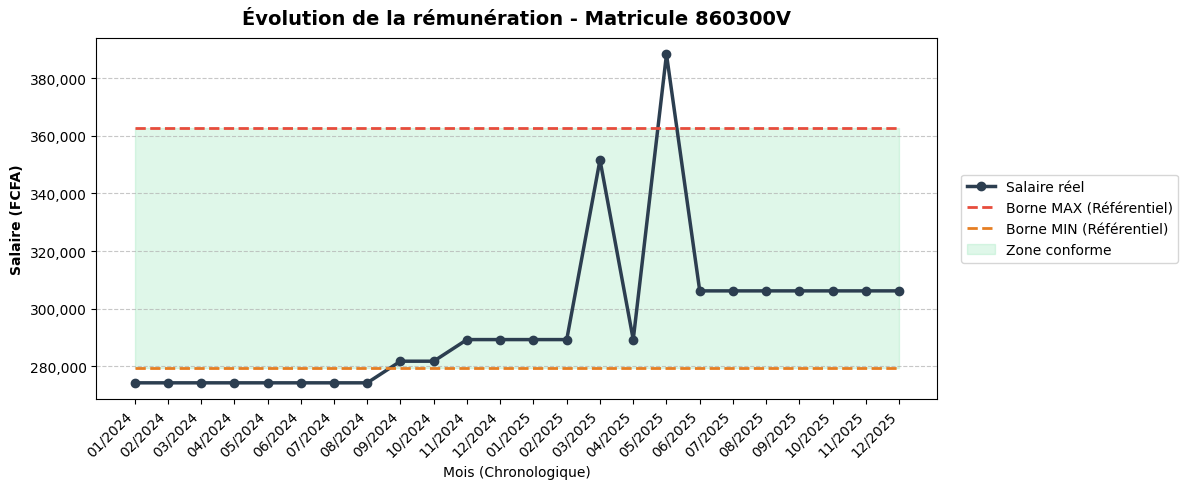

In [22]:
# ==============================================================================
# CODE 2 : VISUALISATION DES SALAIRES (Tableau + Graphique) AVEC TRI CHRONOLOGIQUE
# ==============================================================================
agent_cible = "860300V"

agent_data = (
    base
    .filter(pl.col(col_id) == agent_cible)
    # Création d'une clé de tri sous la forme "YYYYMM" pour forcer la chronologie
    .with_columns(
        (pl.col("mois_annee").str.slice(2, 4) + pl.col("mois_annee").str.slice(0, 2)).alias("cle_tri")
    )
    .sort("cle_tri")  # On trie avec cette nouvelle clé
)

if len(agent_data) == 0:
    print(f"⚠️ Aucun agent trouvé avec le matricule {agent_cible}.")
else:
    # --- 1. AFFICHAGE DU TABLEAU DE DONNÉES AVANT LE GRAPHIQUE ---
    cols_a_afficher = ["mois_annee", col_sal, "Statut", "min_bareme", "max_bareme", "GRADE", "emploi"]
    cols_exist = [c for c in cols_a_afficher if c in agent_data.columns]
    
    print("=" * 80)
    print(f"DÉTAIL MENSUEL POUR L'AGENT : {agent_cible} (Grade observé : {agent_data['GRADE'][0] if 'GRADE' in agent_data.columns else '?'})")
    print("=" * 80)
    print(agent_data.select(cols_exist))
    print("\n") # Espace avant le graphique
    
    # --- 2. PRÉPARATION DES DONNÉES GRAPHIQUES ---
    # Pour que ce soit plus joli sur le graphique, on peut afficher "MM/AAAA"
    mois = [(m[:2] + "/" + m[2:]) for m in agent_data["mois_annee"].to_list()]
    
    salaires = agent_data[col_sal].to_list()
    
    # Gestion des valeurs nulles (si le référentiel est introuvable)
    min_ref = agent_data["min_bareme"].fill_null(0).to_list()
    max_ref = agent_data["max_bareme"].fill_null(0).to_list()
    
    # --- 3. DESSIN DU GRAPHIQUE ---
    fig, ax = plt.subplots(figsize=(12, 5))
    
    # 🔵 Salaire réel
    ax.plot(mois, salaires, marker='o', linewidth=2.5, color='#2c3e50', label="Salaire réel")
    
    # 🔴 MAX
    if sum(max_ref) > 0:
        ax.plot(mois, max_ref, linestyle='--', linewidth=2, color='#e74c3c', label="Borne MAX (Référentiel)")
    
    # 🟠 MIN
    if sum(min_ref) > 0:
        ax.plot(mois, min_ref, linestyle='--', linewidth=2, color='#e67e22', label="Borne MIN (Référentiel)")
    
        # 🟢 Zone conforme (option très utile visuellement)
        ax.fill_between(mois, min_ref, max_ref, color='#2ecc71', alpha=0.15, label="Zone conforme")
    
    # --- 4. DESIGN ESTHÉTIQUE ---
    ax.set_title(f"Évolution de la rémunération - Matricule {agent_cible}", fontsize=14, fontweight='bold', pad=10)
    ax.set_ylabel("Salaire (FCFA)", fontweight='bold')
    ax.set_xlabel("Mois (Chronologique)")
    
    # Format des nombres (ex: 2 000 000 au lieu de 2e6)
    ax.yaxis.set_major_formatter(
        ticker.FuncFormatter(lambda x, p: format(int(x), ','))
    )
    
    # Rotation des mois pour une meilleure lisibilité
    plt.xticks(rotation=45, ha='right')
    
    # Légende + grille
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()


## 13. Résumé

Exécutez cette cellule après avoir exploré les résultats ci-dessus.

In [23]:
print("=" * 60)
print("RÉSUMÉ")
print("=" * 60)

n_lignes_hors = len(hors)
n_agents_hors = hors[col_id].n_unique()
n_agents_total_base = base[col_id].n_unique()

print(f"\nLignes hors barème    : {n_lignes_hors:,} (agent × mois)")
print(f"Agents uniques hors   : {n_agents_hors:,}")
print(f"Agents total          : {n_agents_total_base:,}")
print(f"% agents hors barème  : {100*n_agents_hors/n_agents_total_base:.1f}%")

if "ecart_pct" in hors.columns:
    n_faible = int((hors["ecart_pct"].abs() <= 5).sum())
    n_modere = int(((hors["ecart_pct"].abs() > 5) & (hors["ecart_pct"].abs() <= 30)).sum())
    n_fort = int((hors["ecart_pct"].abs() > 30).sum())
    print(f"\nÉcart ≤ 5%  (cas limites)      : {n_faible:,}")
    print(f"Écart 5-30% (modéré)           : {n_modere:,}")
    print(f"Écart > 30% (fort, à vérifier) : {n_fort:,}")
    

RÉSUMÉ

Lignes hors barème    : 447,602 (agent × mois)
Agents uniques hors   : 116,678
Agents total          : 311,649
% agents hors barème  : 37.4%

Écart ≤ 5%  (cas limites)      : 811
Écart 5-30% (modéré)           : 355,332
Écart > 30% (fort, à vérifier) : 91,459


ANALYSE DE LA SAISONNALITÉ
1. Effet saisonnier pur (Moyenne selon le mois de l'année) :
shape: (12, 3)
┌───────────┬───────────┬───────────────┐
│ mois_seul ┆ Nb_lignes ┆ Salaire_moyen │
│ ---       ┆ ---       ┆ ---           │
│ str       ┆ u32       ┆ f64           │
╞═══════════╪═══════════╪═══════════════╡
│ 01        ┆ 554694    ┆ 468992.0      │
│ 02        ┆ 562949    ┆ 472533.0      │
│ 03        ┆ 568620    ┆ 454476.0      │
│ 04        ┆ 566791    ┆ 454528.0      │
│ 05        ┆ 573594    ┆ 451967.0      │
│ …         ┆ …         ┆ …             │
│ 08        ┆ 583528    ┆ 447988.0      │
│ 09        ┆ 586880    ┆ 435704.0      │
│ 10        ┆ 588263    ┆ 428494.0      │
│ 11        ┆ 587251    ┆ 422045.0      │
│ 12        ┆ 586273    ┆ 421898.0      │
└───────────┴───────────┴───────────────┘

→ Écart maximum entre le mois le plus 'favorable' et le moins favorable : +12.00%
→ CONCLUSION : Forte variation ! Une saisonnalité ou un choc ponctuel affecte notablement cette vari

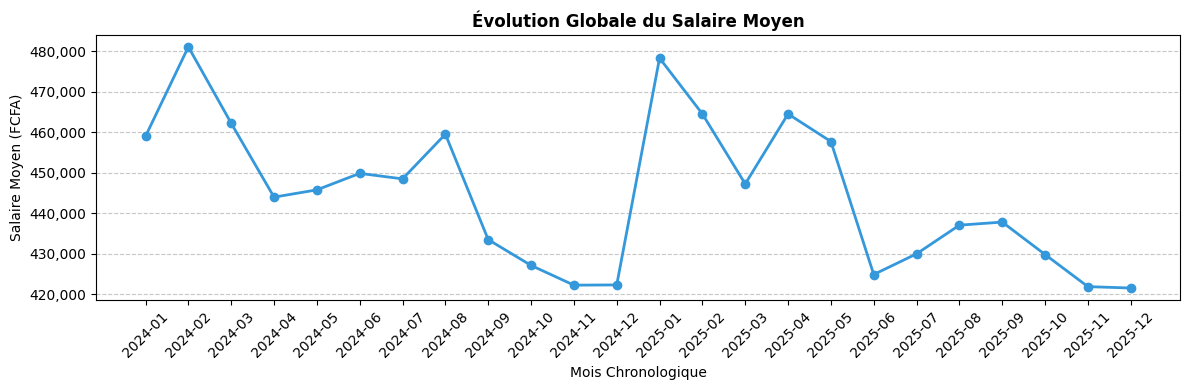

In [ ]:
# ==============================================================================
# VÉRIFICATION DE LA SAISONNALITÉ DU SALAIRE
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import polars as pl

print("=" * 60)
print("ANALYSE DE LA SAISONNALITÉ")
print("=" * 60)

# Extraction du mois isolé (les 2 premiers caractères de mois_annee "MMYYYY")
base_saison = base.with_columns([
    pl.col("mois_annee").str.slice(0, 2).alias("mois_seul"),
    (pl.col("mois_annee").str.slice(2, 4) + "-" + pl.col("mois_annee").str.slice(0, 2)).alias("chrono")
])

# 1. MOYENNE PAR MOIS (Toutes années confondues)
saison_mois = (
    base_saison.group_by("mois_seul")
    .agg([
        pl.len().alias("Nb_lignes"),
        pl.col(col_sal).mean().round(0).alias("Salaire_moyen"),
    ])
    .sort("mois_seul")
)
print("1. Effet saisonnier pur (Moyenne selon le mois de l'année) :")
print(saison_mois)

# 2. ÉCARTS TYPES DU MOIS
# Calculer l'écart en % entre le mois le plus élevé et le mois le plus bas
max_sal = saison_mois["Salaire_moyen"].max()
min_sal = saison_mois["Salaire_moyen"].min()
ecart_pct = ((max_sal - min_sal) / min_sal) * 100

print(f"\n→ Écart maximum entre le mois le plus 'favorable' et le moins favorable : +{ecart_pct:.2f}%")
if ecart_pct < 2:
    print("→ CONCLUSION : Très faible variation. La variable ne souffre pas de saisonnalité marquante.")
elif ecart_pct < 5:
    print("→ CONCLUSION : Variation modérée. Légère saisonnalité ou particularités sur certains mois.")
else:
    print("→ CONCLUSION : Forte variation ! Une saisonnalité ou un choc ponctuel affecte notablement cette variable.")

# 3. GRAPHIQUE CHRONOLOGIQUE GLOBAL
chrono_data = (
    base_saison.group_by("chrono")
    .agg(pl.col(col_sal).mean().round(0).alias("Salaire_moyen"))
    .sort("chrono")
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(chrono_data["chrono"].to_list(), chrono_data["Salaire_moyen"].to_list(), 
        marker='o', linestyle='-', color='#3498db', linewidth=2)

ax.set_title("Évolution Globale du Salaire Moyen", fontweight="bold")
ax.set_xlabel("Mois Chronologique")
ax.set_ylabel("Salaire Moyen (FCFA)")
plt.xticks(rotation=45)
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Formatage des y pour lisibilité
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

plt.tight_layout()
plt.show()


In [7]:
mois_incoherents = (
    base.with_columns(
        pl.when(
            pl.col("Statut").is_in([
                "Inférieur au minimum du barème",
                "Supérieur au maximum du barème"
            ])
        )
        .then(1)
        .otherwise(0)
        .alias("flag_hors_bareme")
    )
    .group_by(col_id)
    .agg(
        pl.col("flag_hors_bareme").sum().alias("nombre_de_mois_incoherents")
    )
)

In [12]:
agents_moins_5_mois = mois_incoherents.filter(
    (pl.col("nombre_de_mois_incoherents") > 0) &
    (pl.col("nombre_de_mois_incoherents") <= 5)
)

In [13]:
agents_moins_5_mois

matricule,nombre_de_mois_incoherents
str,i32
"""902554W""",1
"""898014Q""",1
"""836392R""",4
"""873284S""",1
"""284069F""",1
…,…
"""908007C""",5
"""283944Y""",1
"""871500D""",1
